# Задание 5. Исследовательский анализ SMS-данных (EDA)

Анализ выполняется на очищенном наборе `data/processed/sms_clean.csv` (результат задания 4) **до обучения и без подбора
параметров по тестовой выборке**: на этом этапе ничего не обучается. Ноутбук можно перезапустить целиком —
графики в `docs/figures/` и файл `docs/05_EDA_FINDINGS.md` пересоздаются из данных.

In [1]:
import os, re, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'manage.py').exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

FIG = ROOT / 'docs/figures'; FIG.mkdir(parents=True, exist_ok=True)
NAMES = {0: 'Безопасные (ham)', 1: 'Спам (spam)'}
COLORS = {0: '#4c78a8', 1: '#e45756'}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.axisbelow': True})

df = pd.read_csv('data/processed/sms_clean.csv', keep_default_na=False)
df['chars'] = df.text_raw.str.len()
df['words'] = df.text_clean.str.split().str.len()
print('Строк:', len(df), '| столбцы:', list(df.columns))
df.head()

Строк: 5137 | столбцы: ['id', 'text_raw', 'label', 'text_clean', 'chars', 'words']


,id,text_raw,label,text_clean,chars,words
0,0,"Go until jurong point, crazy.. Available only ...",0,"go until jurong point, crazy.. available only ...",111,20
1,1,Ok lar... Joking wif u oni...,0,ok lar... joking wif u oni...,29,6
2,2,Free entry in 2 a wkly comp to win FA Cup fina...,1,free entry in <num> a wkly comp to win fa cup ...,155,28
3,3,U dun say so early hor... U c already then say...,0,u dun say so early hor... u c already then say...,49,11
4,4,"Nah I don't think he goes to usf, he lives aro...",0,"nah i don't think he goes to usf, he lives aro...",61,13


## 1. Распределение классов

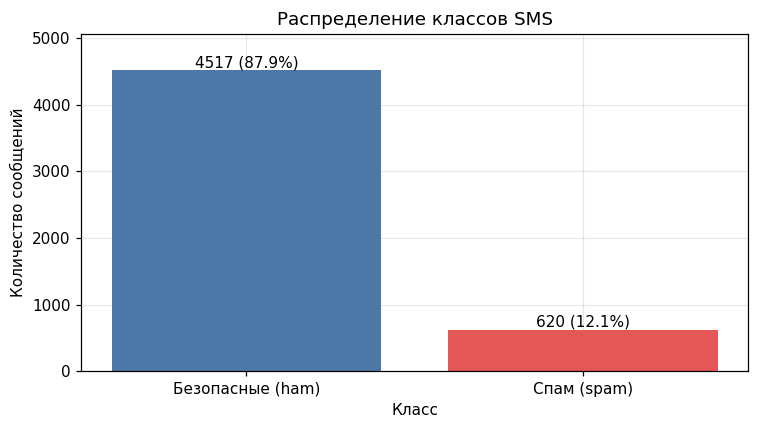

{0: 4517, 1: 620} {0: 87.93, 1: 12.07} | отношение ham:spam = 7.3 : 1


In [2]:
counts = df.label.value_counts().sort_index()
share = counts / counts.sum() * 100
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([NAMES[c] for c in counts.index], counts.values, color=[COLORS[c] for c in counts.index])
for b, n, p in zip(bars, counts.values, share.values):
    ax.text(b.get_x() + b.get_width() / 2, n, f'{n} ({p:.1f}%)', ha='center', va='bottom')
ax.set_title('Распределение классов SMS'); ax.set_xlabel('Класс'); ax.set_ylabel('Количество сообщений')
ax.set_ylim(0, counts.max() * 1.12)
fig.tight_layout(); fig.savefig(FIG / 'sms_classes.png'); plt.show()
print(counts.to_dict(), share.round(2).to_dict(), '| отношение ham:spam = %.1f : 1' % (counts[0] / counts[1]))

## 2. Длина сообщений в символах и словах

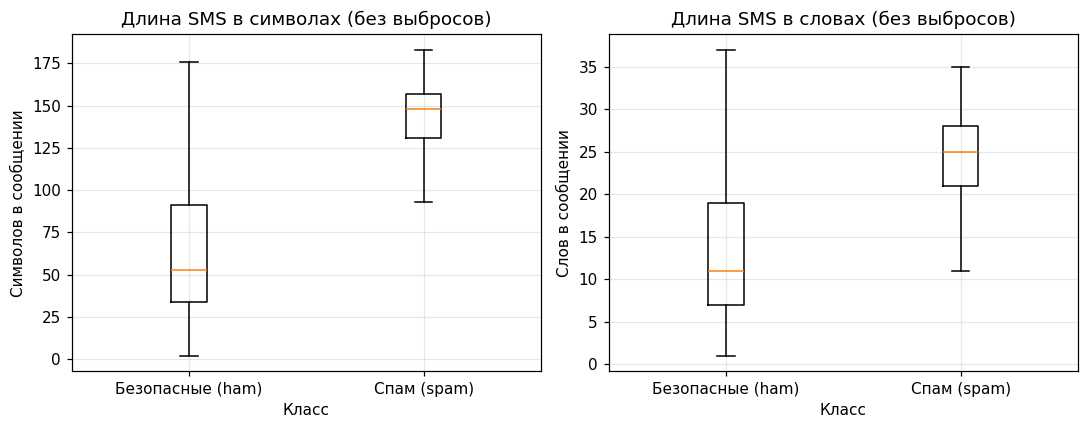

chars             words            
                   mean median  max  mean median  max
Безопасные (ham)   70.9   53.0  910  14.2   11.0  171
Спам (spam)       137.6  148.0  223  23.7   25.0   35

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, title, ylabel in [(axes[0], 'chars', 'Длина SMS в символах', 'Символов в сообщении'),
                               (axes[1], 'words', 'Длина SMS в словах', 'Слов в сообщении')]:
    ax.boxplot([df[df.label == c][col] for c in (0, 1)], tick_labels=[NAMES[0], NAMES[1]], showfliers=False)
    ax.set_title(title + ' (без выбросов)'); ax.set_xlabel('Класс'); ax.set_ylabel(ylabel)
fig.tight_layout(); fig.savefig(FIG / 'sms_lengths.png'); plt.show()
length_stats = df.groupby('label')[['chars', 'words']].agg(['mean', 'median', 'max']).round(1)
length_stats.index = [NAMES[i] for i in length_stats.index]
length_stats

## 3. Топ-20 слов и биграмм по классам (без стоп-слов)

Токены — слова из двух и более букв и служебные токены предобработки (`<url>`, `<num>` …), которые несут информацию.
Стоп-слова — стандартный английский список scikit-learn плюс обрывки сокращений (`ll`, `ve`, `don`). Биграммы строятся
по соседним токенам после удаления стоп-слов.

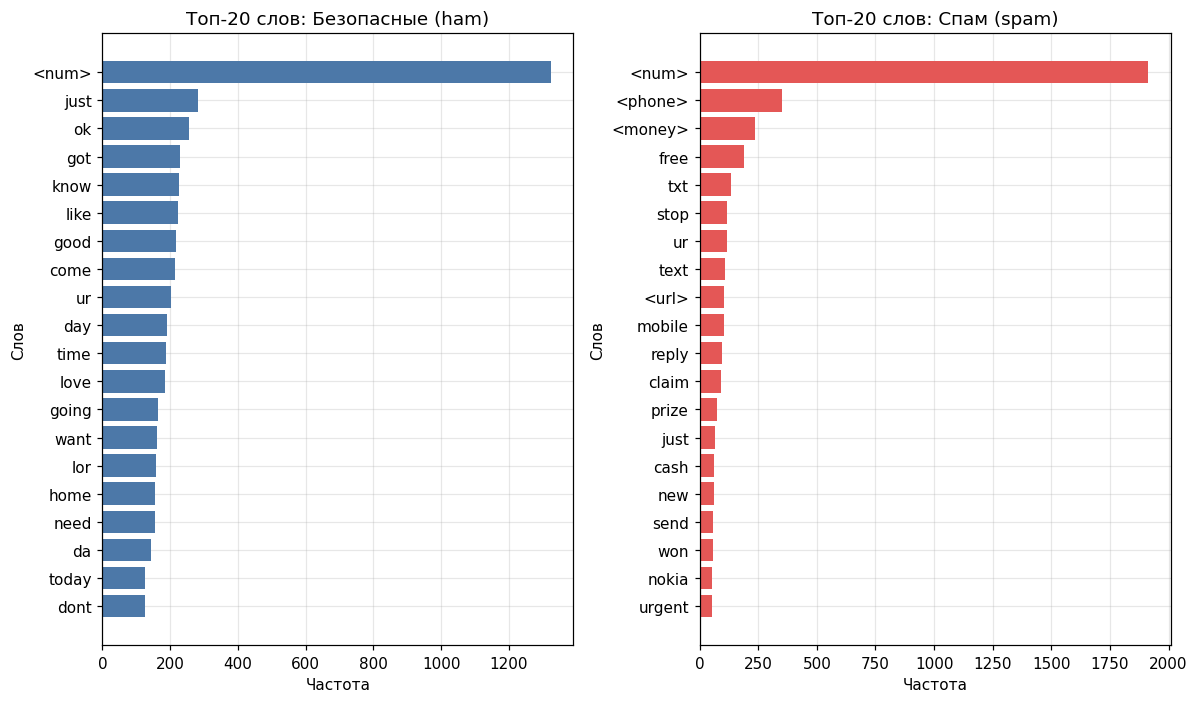

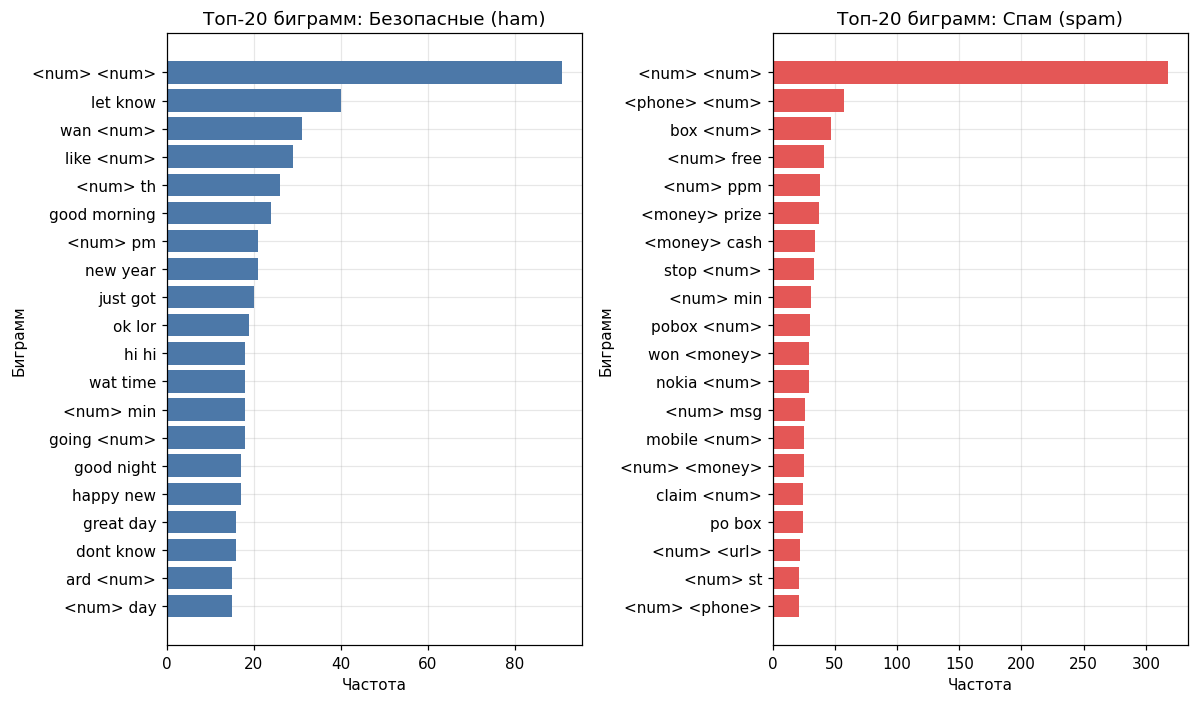

,слова: Безопасные (ham),слова: Спам (spam),биграммы: Безопасные (ham),биграммы: Спам (spam)
0,<num> (1324),<num> (1913),<num> <num> (91),<num> <num> (318)
1,just (282),<phone> (352),let know (40),<phone> <num> (57)
2,ok (256),<money> (235),wan <num> (31),box <num> (47)
3,got (228),free (189),like <num> (29),<num> free (41)
4,know (226),txt (133),<num> th (26),<num> ppm (38)
5,like (224),stop (116),good morning (24),<money> prize (37)
6,good (217),ur (115),<num> pm (21),<money> cash (34)
7,come (215),text (107),new year (21),stop <num> (33)
8,ur (203),<url> (106),just got (20),<num> min (31)
9,day (191),mobile (104),ok lor (19),pobox <num> (30)


In [4]:
STOP = set(ENGLISH_STOP_WORDS) | {'ll', 've', 'don', 're'}
TOKEN = re.compile(r"<\w+>|[^\W\d_]{2,}")

def tokens(text):
    return [t for t in TOKEN.findall(text) if t not in STOP]

top_words, top_bigrams = {}, {}
for c in (0, 1):
    seqs = [tokens(t) for t in df[df.label == c].text_clean]
    top_words[c] = Counter(w for s in seqs for w in s).most_common(20)
    top_bigrams[c] = Counter(' '.join(p) for s in seqs for p in zip(s, s[1:])).most_common(20)

def barh_pair(data, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
    for ax, c in zip(axes, (0, 1)):
        labels, values = zip(*data[c][::-1])
        ax.barh(labels, values, color=COLORS[c])
        ax.set_title(f'{title}: {NAMES[c]}'); ax.set_xlabel('Частота'); ax.set_ylabel(title.split()[-1].capitalize())
    fig.tight_layout(); fig.savefig(FIG / fname); plt.show()

barh_pair(top_words, 'Топ-20 слов', 'sms_top_words.png')
barh_pair(top_bigrams, 'Топ-20 биграмм', 'sms_top_bigrams.png')
pd.DataFrame({f'слова: {NAMES[c]}': [f'{w} ({n})' for w, n in top_words[c]] for c in (0, 1)}
             | {f'биграммы: {NAMES[c]}': [f'{w} ({n})' for w, n in top_bigrams[c]] for c in (0, 1)})

## 4. Доля сообщений с `<url>`, `<phone>`, `<money>` и `!` по классам

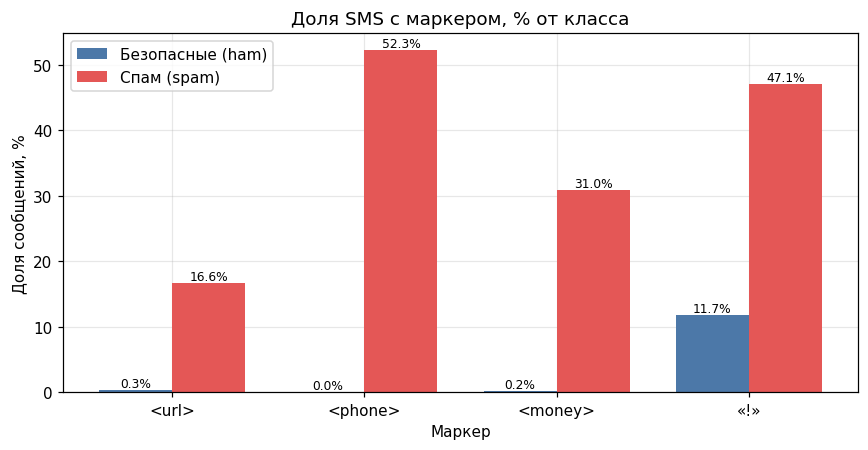

,Безопасные (ham),Спам (spam)
<url>,0.29,16.61
<phone>,0.04,52.26
<money>,0.24,30.97
«!»,11.73,47.10


In [5]:
markers = {'<url>': r'<url>', '<phone>': r'<phone>', '<money>': r'<money>', '«!»': r'!'}
ind = pd.DataFrame({name: [df[df.label == c].text_clean.str.contains(pat).mean() * 100 for c in (0, 1)]
                    for name, pat in markers.items()}, index=[NAMES[0], NAMES[1]]).T
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(ind)); w = .38
for i, c in enumerate((0, 1)):
    vals = ind.iloc[:, i]
    ax.bar(x + (i - .5) * w, vals, w, label=NAMES[c], color=COLORS[c])
    for xi, v in zip(x, vals):
        ax.text(xi + (i - .5) * w, v, f'{v:.1f}%', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(ind.index); ax.legend()
ax.set_title('Доля SMS с маркером, % от класса'); ax.set_xlabel('Маркер'); ax.set_ylabel('Доля сообщений, %')
fig.tight_layout(); fig.savefig(FIG / 'sms_indicators.png'); plt.show()
ind.round(2)

## 5. Выводы (числа вычисляются из данных)

In [6]:
g = lambda col, c, f='mean': getattr(df[df.label == c][col], f)()
only_spam = [w for w, _ in top_words[1] if w not in dict(top_words[0])][:6]
obs = [
    f"**Дисбаланс классов.** Спам — {share[1]:.1f}% ({counts[1]} из {len(df)} SMS), отношение ham:spam ≈ {counts[0]/counts[1]:.1f}:1.",
    f"**Длина.** Спам заметно длиннее: в среднем {g('chars',1):.1f} против {g('chars',0):.1f} символов (медиана {g('chars',1,'median'):.0f} против {g('chars',0,'median'):.0f}) и {g('words',1):.1f} против {g('words',0):.1f} слов.",
    f"**Телефон.** Номер телефона (`<phone>`) есть в {ind.loc['<phone>', NAMES[1]]:.1f}% спама и лишь в {ind.loc['<phone>', NAMES[0]]:.2f}% безопасных SMS — самый сильный одиночный маркер.",
    f"**Сумма с валютой.** `<money>` встречается в {ind.loc['<money>', NAMES[1]]:.1f}% спама и в {ind.loc['<money>', NAMES[0]]:.2f}% безопасных SMS.",
    f"**Ссылки.** `<url>` есть в {ind.loc['<url>', NAMES[1]]:.1f}% спама и в {ind.loc['<url>', NAMES[0]]:.2f}% безопасных SMS: ссылка встречается лишь у части спама, поэтому одного признака «есть ссылка» мало.",
    f"**Восклицательный знак.** «!» есть в {ind.loc['«!»', NAMES[1]]:.1f}% спама и в {ind.loc['«!»', NAMES[0]]:.1f}% безопасных SMS.",
    f"**Лексика.** Среди 20 самых частых слов спама нет в топ-20 безопасных: {', '.join('`'+w+'`' for w in only_spam)}.",
]
for i, o in enumerate(obs, 1):
    print(f'{i}. {o}\n')

1. **Дисбаланс классов.** Спам — 12.1% (620 из 5137 SMS), отношение ham:spam ≈ 7.3:1.

2. **Длина.** Спам заметно длиннее: в среднем 137.6 против 70.9 символов (медиана 148 против 53) и 23.7 против 14.2 слов.

3. **Телефон.** Номер телефона (`<phone>`) есть в 52.3% спама и лишь в 0.04% безопасных SMS — самый сильный одиночный маркер.

4. **Сумма с валютой.** `<money>` встречается в 31.0% спама и в 0.24% безопасных SMS.

5. **Ссылки.** `<url>` есть в 16.6% спама и в 0.29% безопасных SMS: ссылка встречается лишь у части спама, поэтому одного признака «есть ссылка» мало.

6. **Восклицательный знак.** «!» есть в 47.1% спама и в 11.7% безопасных SMS.

7. **Лексика.** Среди 20 самых частых слов спама нет в топ-20 безопасных: `<phone>`, `<money>`, `free`, `txt`, `stop`, `text`.



### Гипотезы для признаков (задание 6)

* Длина, доля заглавных букв и число `!` — признаки давления и «рекламного» стиля.
* Наличие `<url>`, `<phone>`, `<money>` — сильные бинарные признаки; в задании 6 в ручные признаки включены `<url>` и `<money>`,
  а телефон и числа учитываются TF-IDF через токены `<phone>`, `<num>`.
* Слова-призывы (`call`, `free`, `claim`, `reply`, `stop`, `txt`) и их биграммы — основной сигнал для TF-IDF.
* Символьные n-граммы нужны для искажений написания (`fr33`, `b@nk`), которые словные признаки не поймают.

### Как учитывается дисбаланс классов

Спама около 12%, поэтому: (1) разбиение **стратифицированное** (доля спама одинакова в train/val/test);
(2) модели обучаются с `class_weight='balanced'`; (3) качество оценивается по Precision/Recall/F1/F2 и PR-AUC,
а не по Accuracy (константа «всё безопасно» дала бы ≈88%); (4) приоритет — Recall класса «мошенничество».

### Ограничения

Набор англоязычный и содержит спам, а не только финансовое мошенничество; выводы не переносятся на русский и казахский языки.
Анализ выполнен на всём очищенном наборе до обучения, никакие параметры по нему и по тесту не подбирались.

In [7]:
(ROOT / 'docs/05_EDA_FINDINGS.md').write_text(
    '# Задание 5. EDA: численные наблюдения\n\n'
    'Файл создаётся ноутбуком `notebooks/01_eda_sms.ipynb`; все числа вычислены на `data/processed/sms_clean.csv` '
    f'({len(df)} SMS) до обучения моделей.\n\n'
    + '\n'.join(f'{i}. {o}' for i, o in enumerate(obs, 1)) +
    '\n\n## Учёт дисбаланса\n\nСтратифицированное разбиение 70/15/15, `class_weight=\'balanced\'`, метрики Precision/Recall/F1/F2 и PR-AUC '
    'вместо Accuracy. Тестовая выборка в EDA и при подборе параметров не используется.\n\n'
    '## Графики\n\n`docs/figures/`: `sms_classes.png`, `sms_lengths.png`, `sms_top_words.png`, `sms_top_bigrams.png`, `sms_indicators.png`.\n',
    encoding='utf-8')
print('Записан docs/05_EDA_FINDINGS.md; графики:', sorted(p.name for p in FIG.glob('sms_*.png')))

Записан docs/05_EDA_FINDINGS.md; графики: ['sms_classes.png', 'sms_indicators.png', 'sms_lengths.png', 'sms_top_bigrams.png', 'sms_top_words.png']
